# Imports

In [1]:
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# 1-Data raw exploration

#### a-Train data

In [2]:
#Read input 
x_train_df = pd.read_csv('x_train_clean.csv', sep=',')
print("Read x : OK")

#Read output
y_train_df = pd.read_csv('y_train_clean.csv', sep=',')
print("Read y : OK")

Read x : OK
Read y : OK


In [3]:
x_train_df

,Unnamed: 0,Id,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,...,_PACAT1,_PAINDX1,_PA150R2,_PA300R2,_PA30021,_PASTRNG,_PAREC1,_PASTAE1,_RFSEAT2,_RFSEAT3
0,0,0,53,11,11162015,11,16,2015,1100,2015015629,...,2,1,1,2,2,1,1,1,1,1
1,1,1,33,12,12152015,12,15,2015,1200,2015004387,...,9,9,9,9,9,9,9,9,9,9
2,2,2,20,10,10202015,10,20,2015,1100,2015005638,...,3,2,2,2,2,2,4,2,1,1
3,3,3,42,6,6182015,6,18,2015,1100,2015004694,...,1,1,1,1,1,2,2,2,1,1
4,4,4,24,11,11062015,11,6,2015,1100,2015004673,...,9,9,9,9,9,2,9,9,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
328130,328130,328130,49,7,11232015,11,23,2015,1100,2015006796,...,2,1,1,2,2,2,2,2,1,1
328131,328131,328131,51,5,6082015,6,8,2015,1100,2015006482,...,1,1,1,1,1,1,1,1,1,1
328132,328132,328132,39,10,10202015,10,20,2015,1100,2015004898,...,3,2,2,2,2,1,3,2,1,2
328133,328133,328133,33,12,12302015,12,30,2015,1100,2015004449,...,3,2,2,2,2,1,3,2,1,1


#### b-Dataset completion with output

In [4]:
x_train_df_complete = x_train_df.copy()
x_train_df_complete["_MICHD"] = y_train_df["_MICHD"]
x_train_df_complete

,Unnamed: 0,Id,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,...,_PAINDX1,_PA150R2,_PA300R2,_PA30021,_PASTRNG,_PAREC1,_PASTAE1,_RFSEAT2,_RFSEAT3,_MICHD
0,0,0,53,11,11162015,11,16,2015,1100,2015015629,...,1,1,2,2,1,1,1,1,1,-1
1,1,1,33,12,12152015,12,15,2015,1200,2015004387,...,9,9,9,9,9,9,9,9,9,-1
2,2,2,20,10,10202015,10,20,2015,1100,2015005638,...,2,2,2,2,2,4,2,1,1,-1
3,3,3,42,6,6182015,6,18,2015,1100,2015004694,...,1,1,1,1,2,2,2,1,1,-1
4,4,4,24,11,11062015,11,6,2015,1100,2015004673,...,9,9,9,9,2,9,9,1,1,-1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
328130,328130,328130,49,7,11232015,11,23,2015,1100,2015006796,...,1,1,2,2,2,2,2,1,1,-1
328131,328131,328131,51,5,6082015,6,8,2015,1100,2015006482,...,1,1,1,1,1,1,1,1,1,-1
328132,328132,328132,39,10,10202015,10,20,2015,1100,2015004898,...,2,2,2,2,1,3,2,1,2,-1
328133,328133,328133,33,12,12302015,12,30,2015,1100,2015004449,...,2,2,2,2,1,3,2,1,1,-1


#### c-Dataset understanding

In [5]:
#MICHD indicator analysis
print(f"Unique values : {x_train_df_complete["_MICHD"].unique()}")

#Input/Output columns
print(f"Inputs/outputs : {x_train_df_complete.columns}")

#Unique ids number
len(x_train_df_complete["Id"].unique())

Unique values : [-1  1]
Inputs/outputs : Index(['Unnamed: 0', 'Id', '_STATE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY',
       'IYEAR', 'DISPCODE', 'SEQNO', '_PSU', 'MENTHLTH', 'HLTHPLN1',
       'PERSDOC2', 'BLOODCHO', 'CVDSTRK3', 'ASTHMA3', 'CHCOCNCR', 'CHCCOPD1',
       'ADDEPEV2', 'CHCKIDNY', 'SEX', 'MARITAL', 'EDUCA', 'RENTHOM1',
       'EMPLOY1', 'QSTVER', '_STSTR', '_RAWRAKE', '_WT2RAKE', '_DUALUSE',
       '_LLCPWT', '_RFHLTH', '_HCVU651', '_RFHYPE5', '_CHOLCHK', '_LTASTH1',
       '_CASTHM1', '_ASTHMS1', '_PRACE1', '_MRACE1', '_HISPANC', '_RACE',
       '_RACEG21', '_RACEGR3', '_AGEG5YR', '_AGE65YR', '_AGE80', '_AGE_G',
       '_RFBMI5', '_CHLDCNT', '_EDUCAG', '_INCOMG', '_SMOKER3', '_RFSMOK3',
       'DRNKANY5', 'DROCDY3_', '_RFBING5', '_DRNKWEK', '_RFDRHV5', '_MISFRTN',
       '_MISVEGN', '_FRTRESP', '_VEGRESP', '_FRTLT1', '_VEGLT1', '_FRT16',
       '_VEG23', '_FRUITEX', '_VEGETEX', '_TOTINDA', 'MAXVO2_', 'FC60_',
       'PAMISS1_', '_PACAT1', '_PAINDX1', '_PA150R2', '_PA300R2',

328135

In [6]:
L_feature = ['Id', '_STATE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY',
       'IYEAR', 'DISPCODE', 'SEQNO', '_PSU', 'MENTHLTH', 'HLTHPLN1',
       'PERSDOC2', 'BLOODCHO', 'CVDSTRK3', 'ASTHMA3', 'CHCOCNCR', 'CHCCOPD1',
       'ADDEPEV2', 'CHCKIDNY', 'SEX', 'MARITAL', 'EDUCA', 'RENTHOM1',
       'EMPLOY1', 'QSTVER', '_STSTR', '_RAWRAKE', '_WT2RAKE', '_DUALUSE',
       '_LLCPWT', '_RFHLTH', '_HCVU651', '_RFHYPE5', '_CHOLCHK', '_LTASTH1',
       '_CASTHM1', '_ASTHMS1', '_PRACE1', '_MRACE1', '_HISPANC', '_RACE',
       '_RACEG21', '_RACEGR3', '_AGEG5YR', '_AGE65YR', '_AGE80', '_AGE_G',
       '_RFBMI5', '_CHLDCNT', '_EDUCAG', '_INCOMG', '_SMOKER3', '_RFSMOK3',
       'DRNKANY5', 'DROCDY3_', '_RFBING5', '_DRNKWEK', '_RFDRHV5', '_MISFRTN',
       '_MISVEGN', '_FRTRESP', '_VEGRESP', '_FRTLT1', '_VEGLT1', '_FRT16',
       '_VEG23', '_FRUITEX', '_VEGETEX', '_TOTINDA', 'MAXVO2_', 'FC60_',
       'PAMISS1_', '_PACAT1', '_PAINDX1', '_PA150R2', '_PA300R2', '_PA30021',
       '_PASTRNG', '_PAREC1', '_PASTAE1', '_RFSEAT2', '_RFSEAT3', '_MICHD']

Conclusion: creation of "basic" (from intuition) list of interest 

Actually: many list of interests can be chosen. The following one is a health list of interest, ie with health features only (I did not check from website, hence there could be mistakes). 

In [7]:
L_interest_health = ['MENTHLTH', 'HLTHPLN1',
       'PERSDOC2', 'BLOODCHO', 'CVDSTRK3', 'ASTHMA3', 'CHCOCNCR', 'CHCCOPD1',
       'ADDEPEV2', 'CHCKIDNY', 'QSTVER', '_STSTR', '_RAWRAKE', '_WT2RAKE', '_DUALUSE',
       '_LLCPWT', '_RFHLTH', '_HCVU651', '_RFHYPE5', '_CHOLCHK', '_LTASTH1',
       '_CASTHM1', '_ASTHMS1', '_SMOKER3', '_RFSMOK3',
       'DRNKANY5', 'DROCDY3_', '_RFBING5', '_DRNKWEK', '_RFDRHV5', '_MISFRTN',
       '_MISVEGN', '_FRTRESP', '_VEGRESP', '_FRTLT1', '_VEGLT1', '_FRT16',
       '_VEG23', '_FRUITEX', '_VEGETEX', '_TOTINDA', 'MAXVO2_', 'FC60_',
       'PAMISS1_', '_PACAT1', '_PAINDX1', '_PA150R2', '_PA300R2', '_PA30021',
       '_PASTRNG', '_PAREC1', '_PASTAE1', '_RFSEAT2', '_RFSEAT3', '_MICHD']

#### d-Description statistics

In [8]:
x_train_df_complete["_MICHD"].describe()

count    328135.000000
mean         -0.823396
std           0.567468
min          -1.000000
25%          -1.000000
50%          -1.000000
75%          -1.000000
max           1.000000
Name: _MICHD, dtype: float64

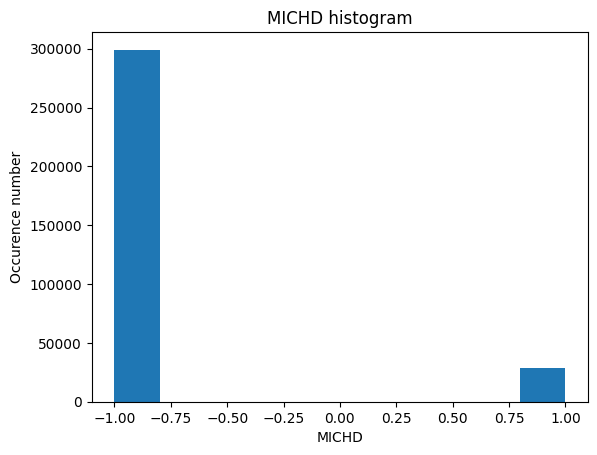

In [9]:
plt.hist(x_train_df_complete["_MICHD"])
plt.xlabel("MICHD")
plt.ylabel("Occurence number")
plt.title("MICHD histogram")
plt.show()

Conclusion: there seems to be more -1 than 1.

# 2-Health features

#### a-Dependency graphs

In [10]:
x_train_df_health = x_train_df_complete[L_interest_health]
x_train_df_health

,MENTHLTH,HLTHPLN1,PERSDOC2,BLOODCHO,CVDSTRK3,ASTHMA3,CHCOCNCR,CHCCOPD1,ADDEPEV2,CHCKIDNY,...,_PAINDX1,_PA150R2,_PA300R2,_PA30021,_PASTRNG,_PAREC1,_PASTAE1,_RFSEAT2,_RFSEAT3,_MICHD
0,5,1,1,1,2,2,2,2,1,2,...,1,1,2,2,1,1,1,1,1,-1
1,88,1,1,1,2,2,2,2,2,2,...,9,9,9,9,9,9,9,9,9,-1
2,77,1,1,1,2,2,2,2,2,2,...,2,2,2,2,2,4,2,1,1,-1
3,88,1,1,1,2,2,2,2,2,2,...,1,1,1,1,2,2,2,1,1,-1
4,88,1,9,1,2,2,2,2,2,2,...,9,9,9,9,2,9,9,1,1,-1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
328130,88,1,1,1,2,2,1,2,2,2,...,1,1,2,2,2,2,2,1,1,-1
328131,88,1,1,1,2,2,2,2,2,2,...,1,1,1,1,1,1,1,1,1,-1
328132,1,1,1,1,2,2,2,2,1,2,...,2,2,2,2,1,3,2,1,2,-1
328133,88,1,1,1,2,1,2,2,2,2,...,2,2,2,2,1,3,2,1,1,-1


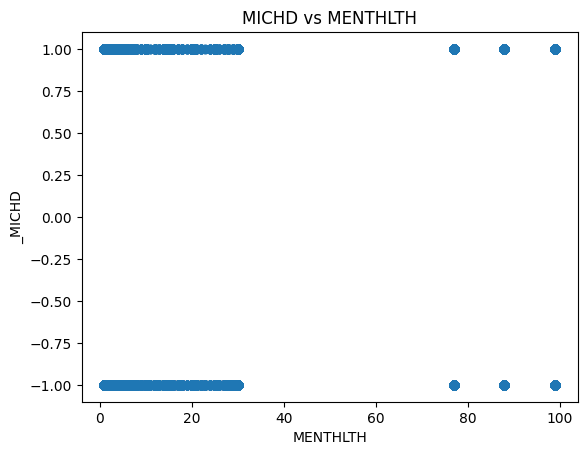

In [11]:
feature = "MENTHLTH"
plt.scatter(x_train_df_health[feature], x_train_df_health["_MICHD"])
plt.xlabel(feature)
plt.ylabel("_MICHD")
plt.title(f"MICHD vs {feature}")
plt.show()

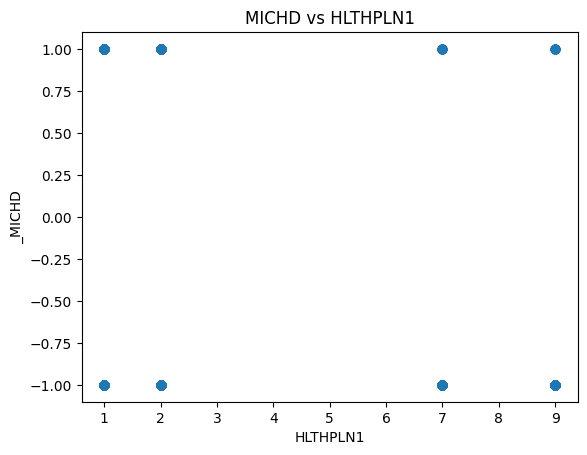

In [12]:
feature = "HLTHPLN1"
plt.scatter(x_train_df_health[feature], x_train_df_health["_MICHD"])
plt.xlabel(feature)
plt.ylabel("_MICHD")
plt.title(f"MICHD vs {feature}")
plt.show()

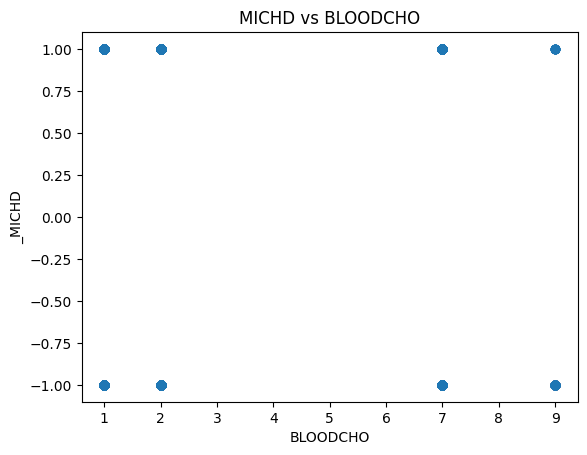

In [13]:
feature = "BLOODCHO"
plt.scatter(x_train_df_health[feature], x_train_df_health["_MICHD"])
plt.xlabel(feature)
plt.ylabel("_MICHD")
plt.title(f"MICHD vs {feature}")
plt.show()

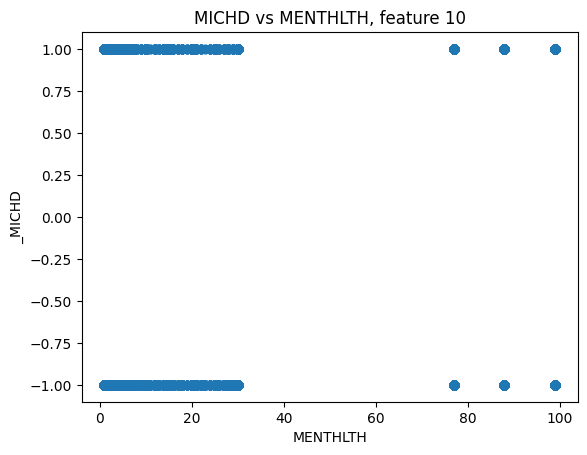

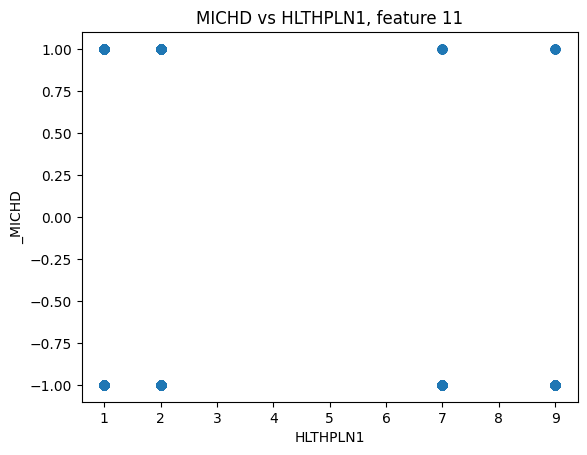

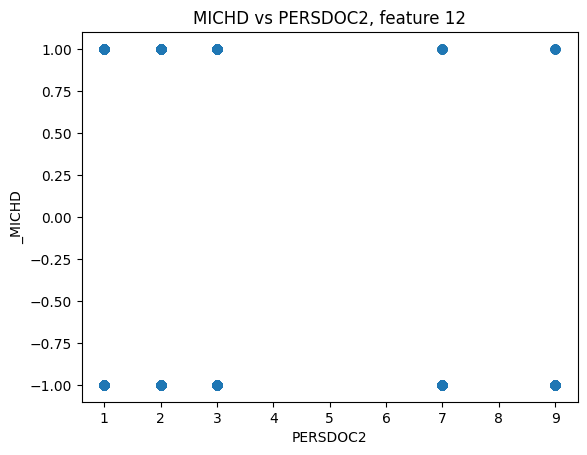

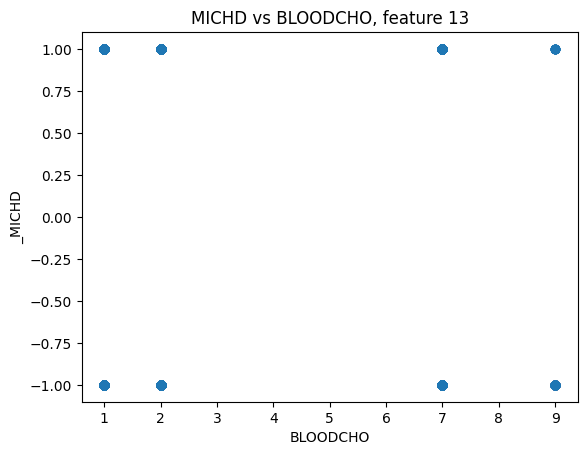

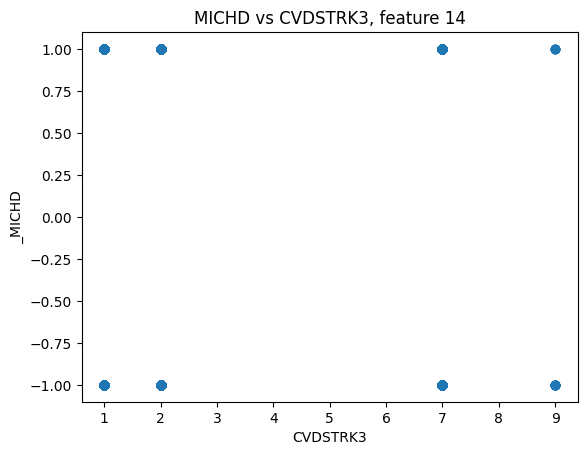

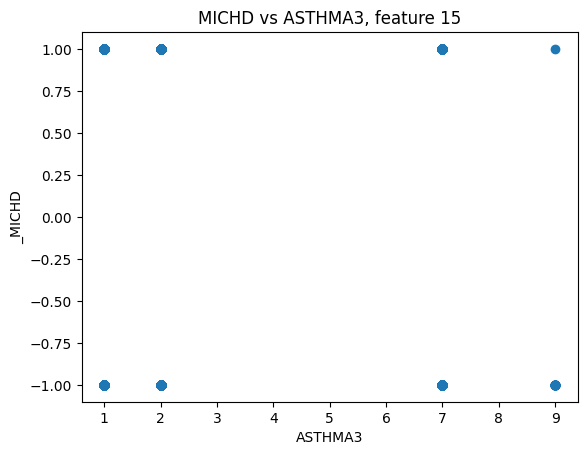

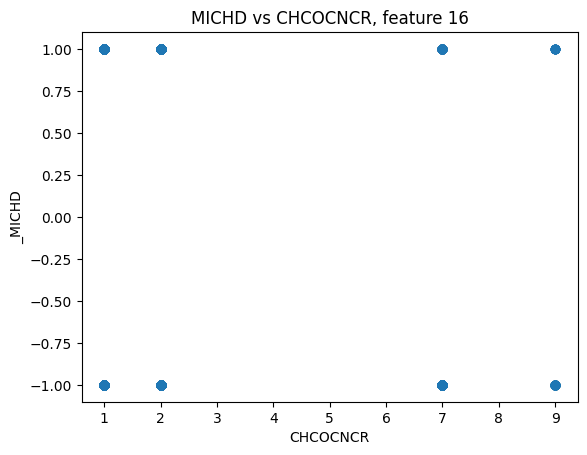

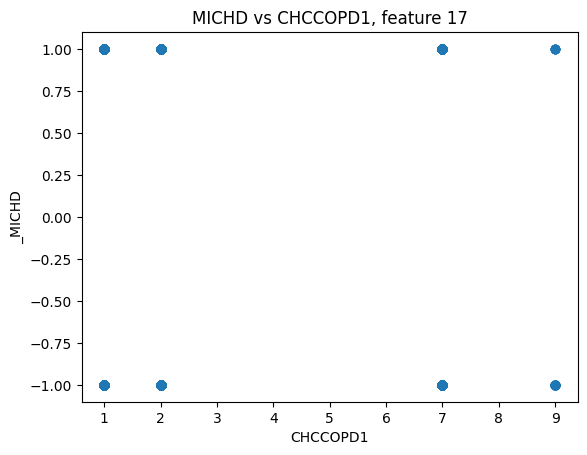

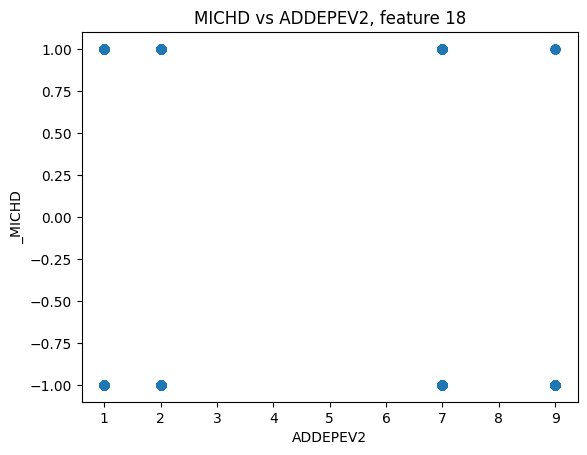

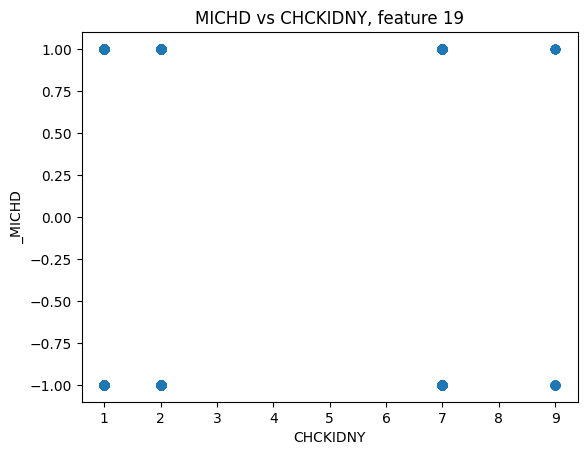

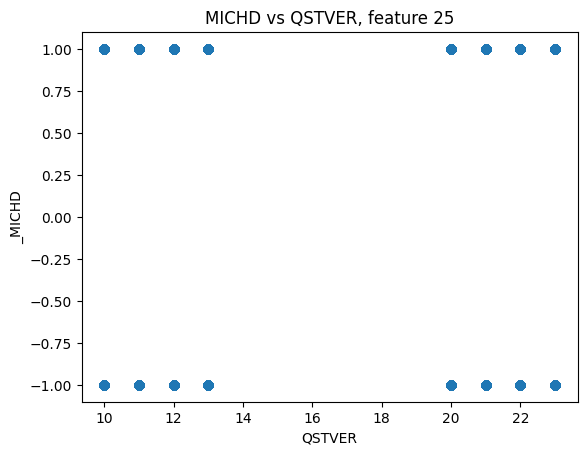

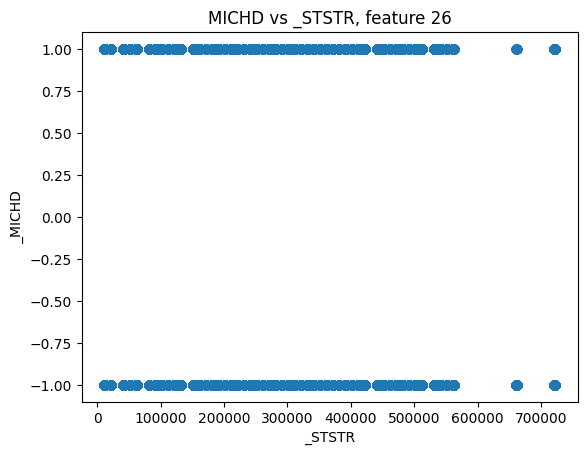

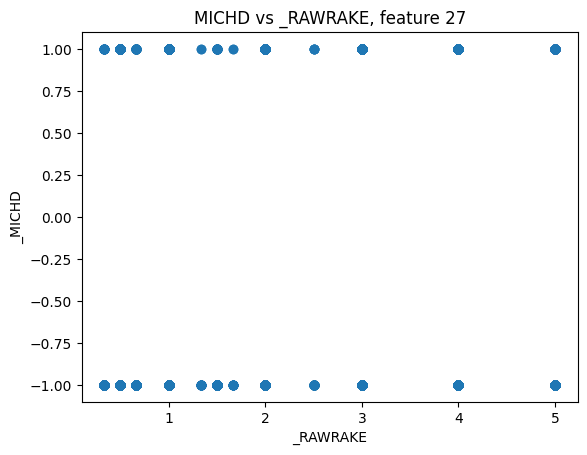

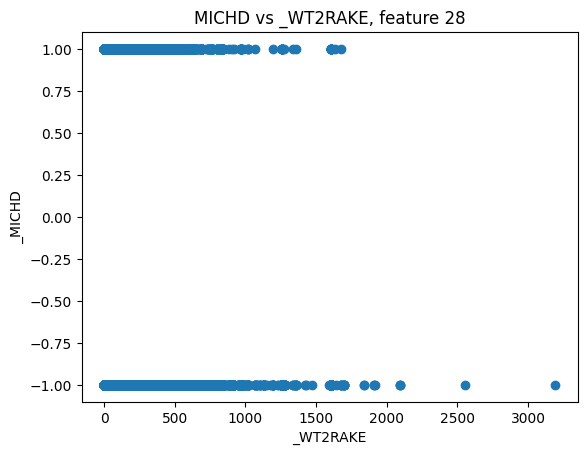

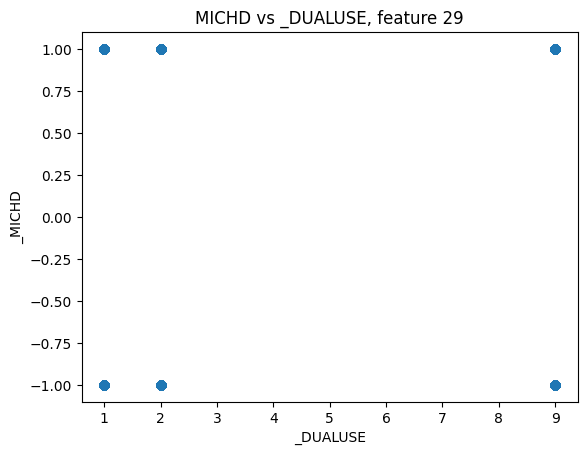

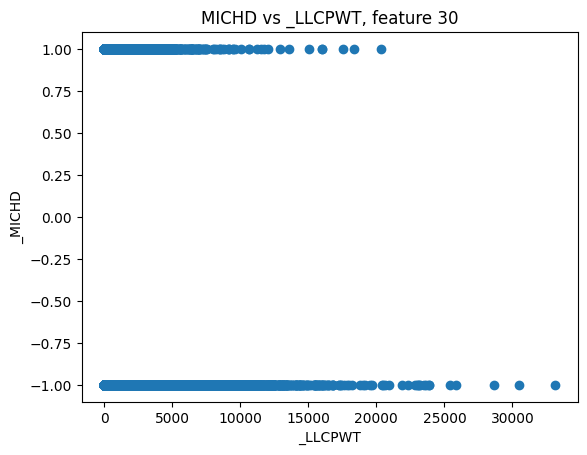

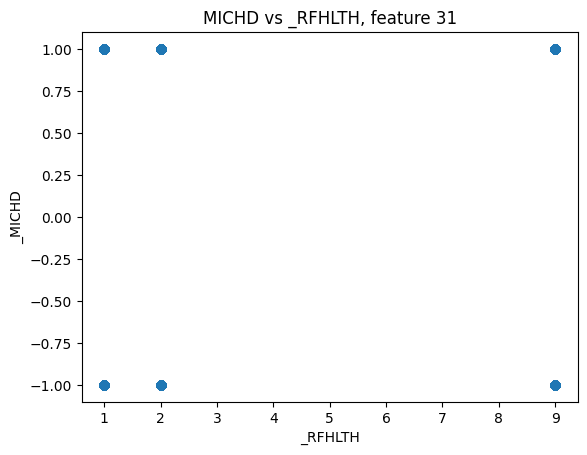

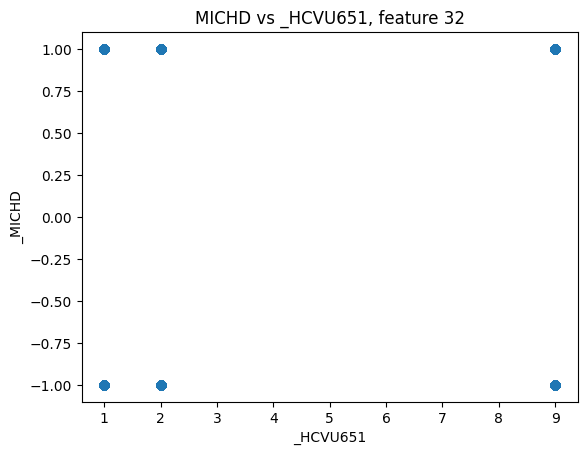

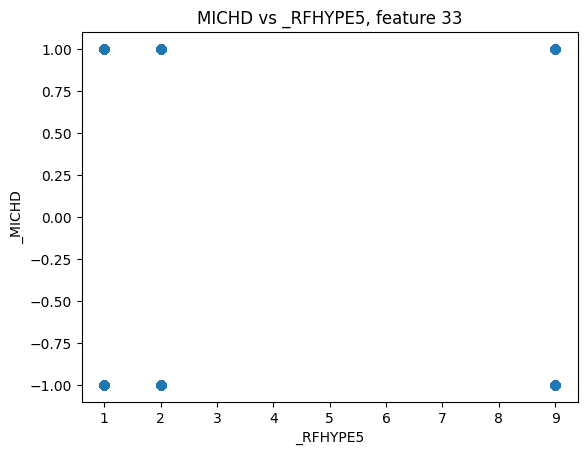

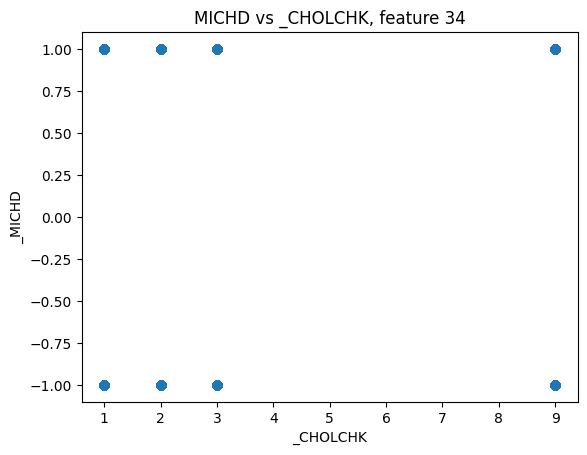

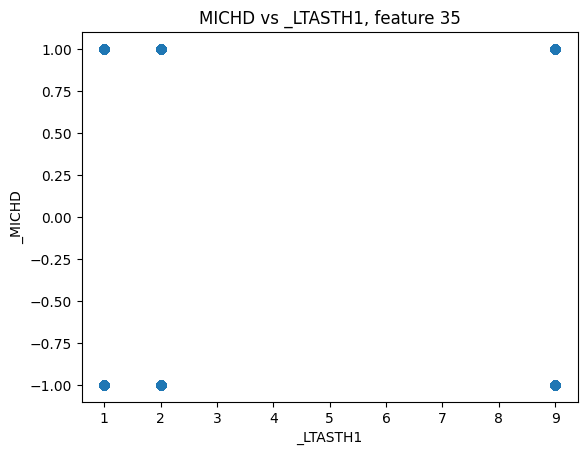

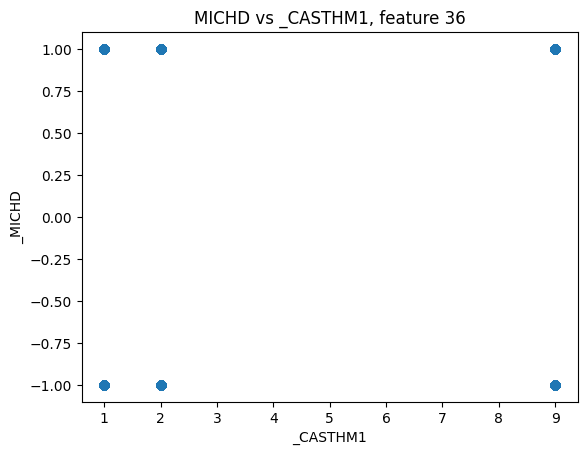

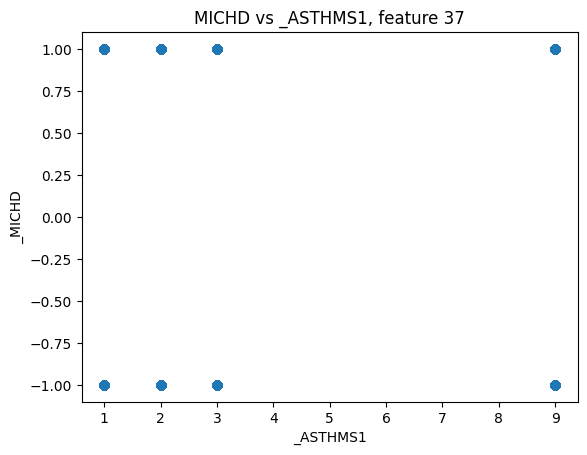

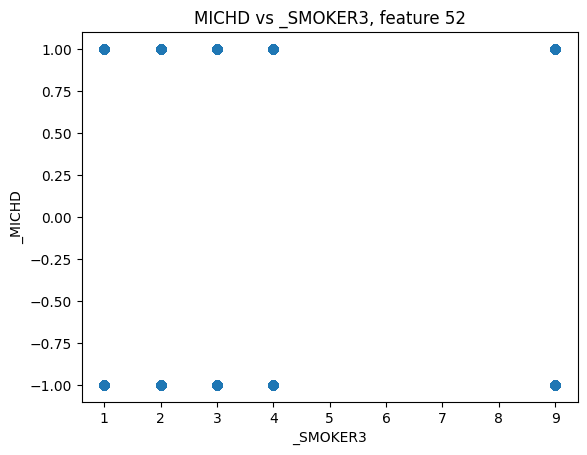

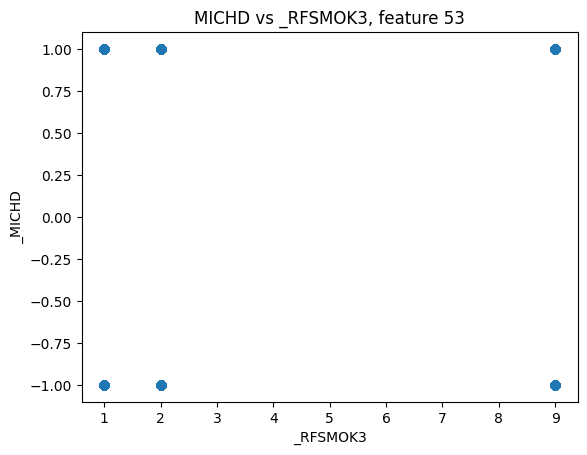

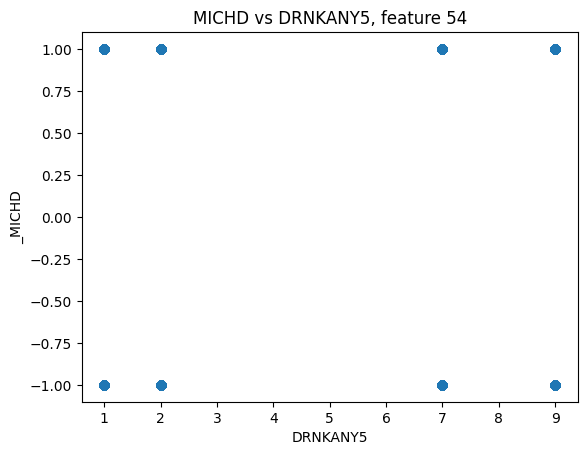

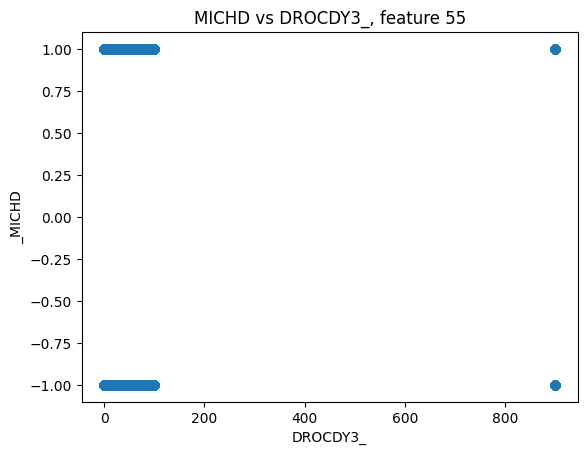

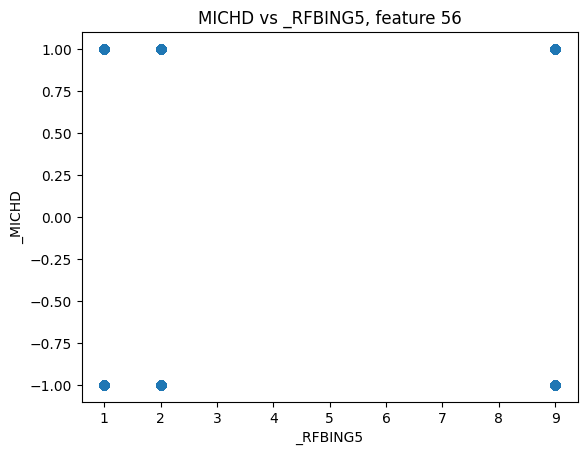

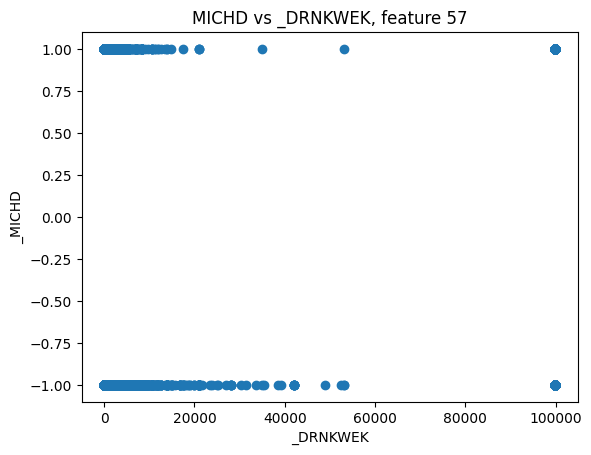

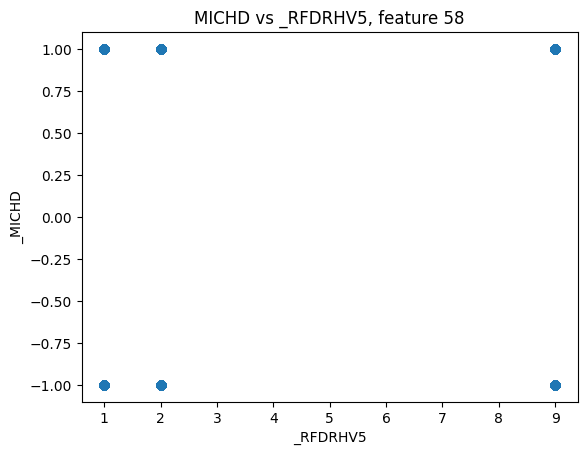

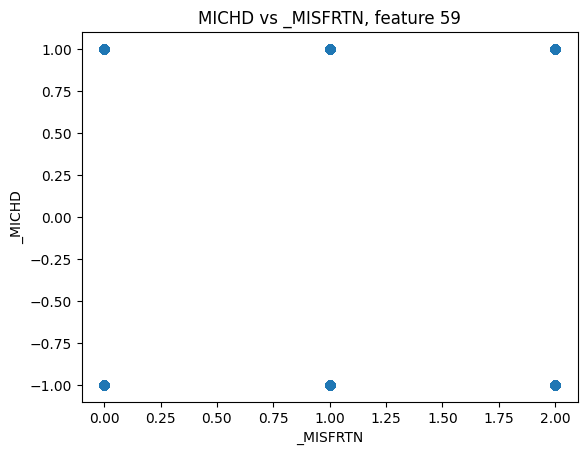

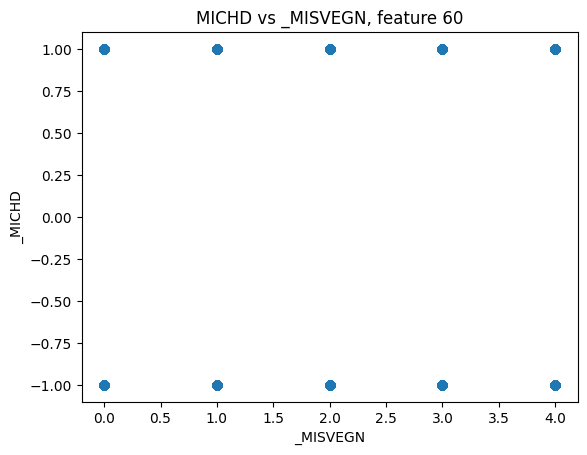

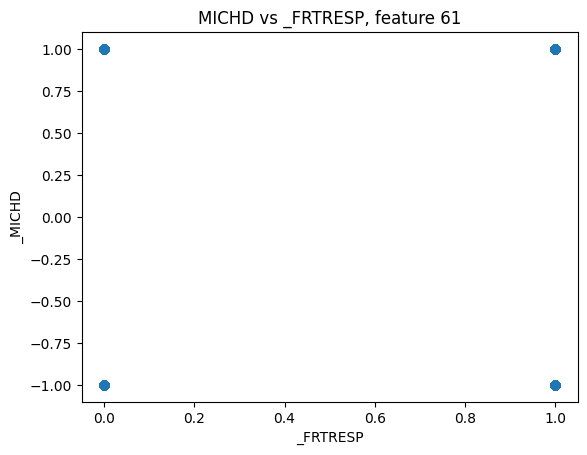

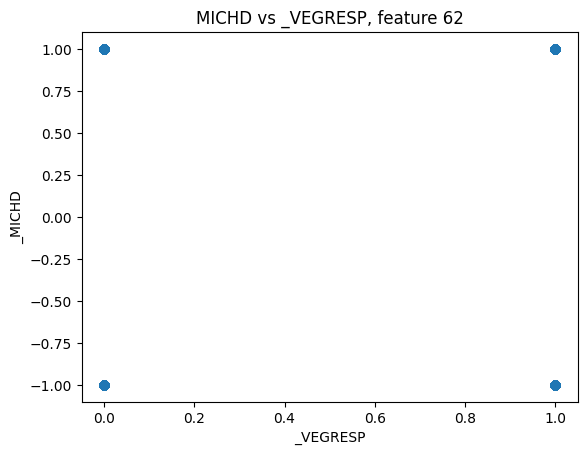

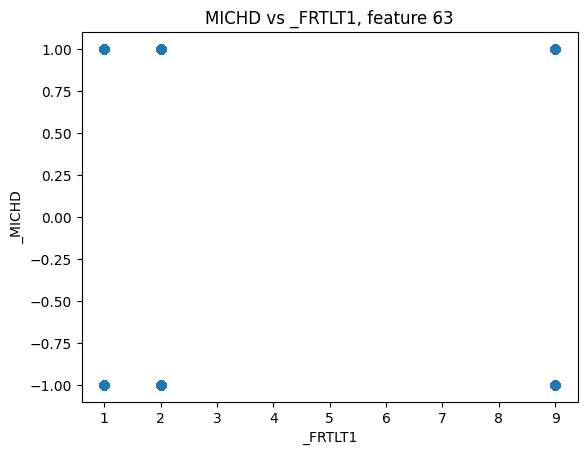

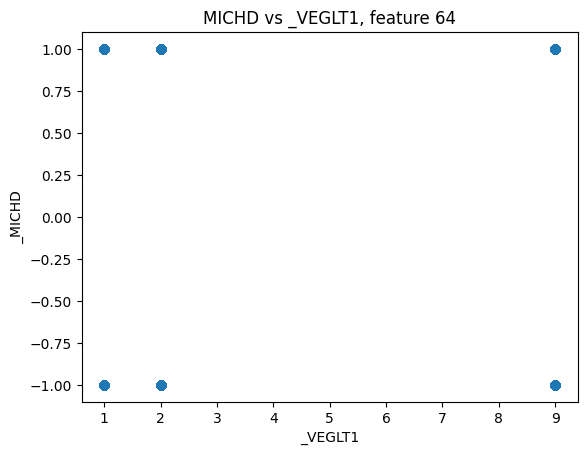

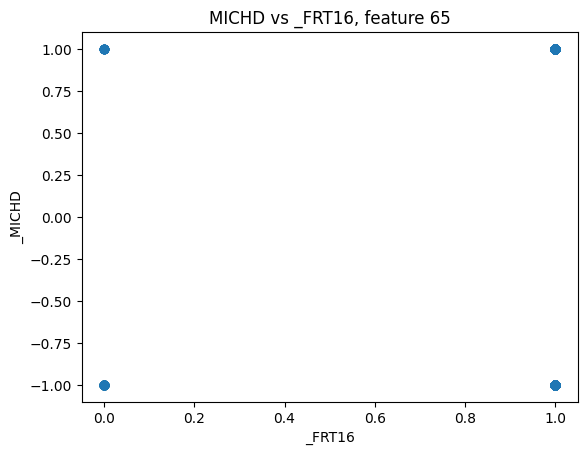

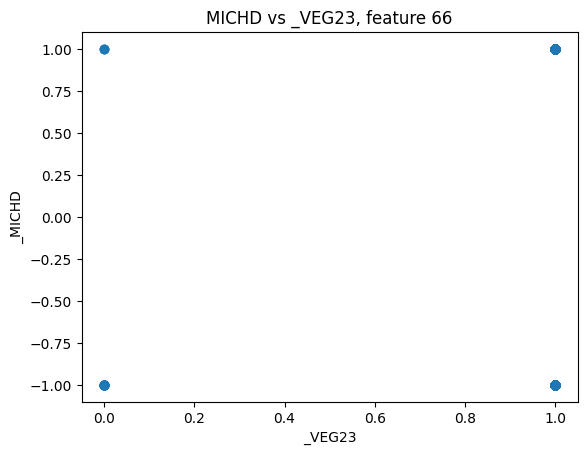

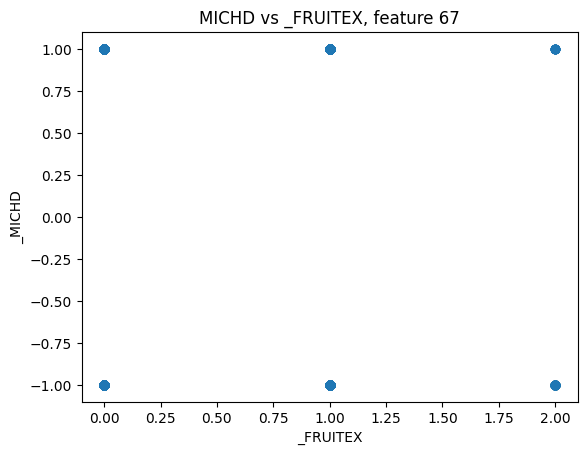

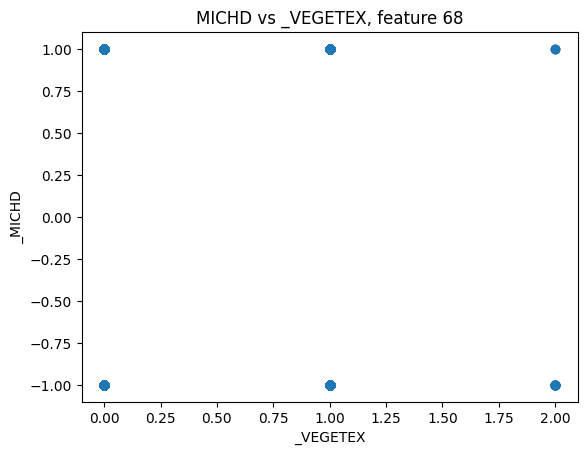

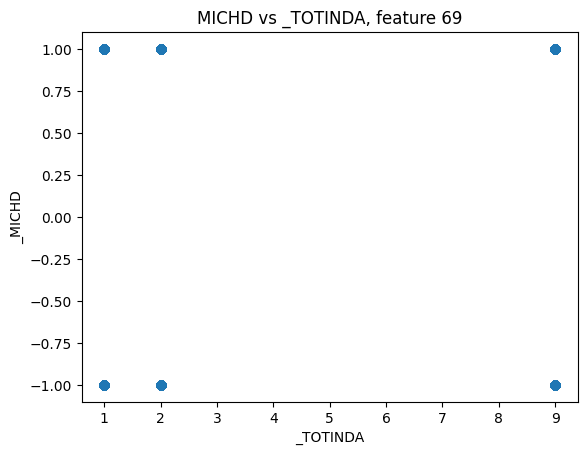

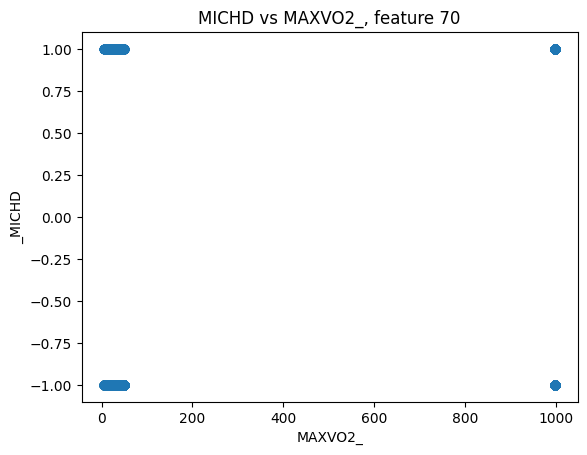

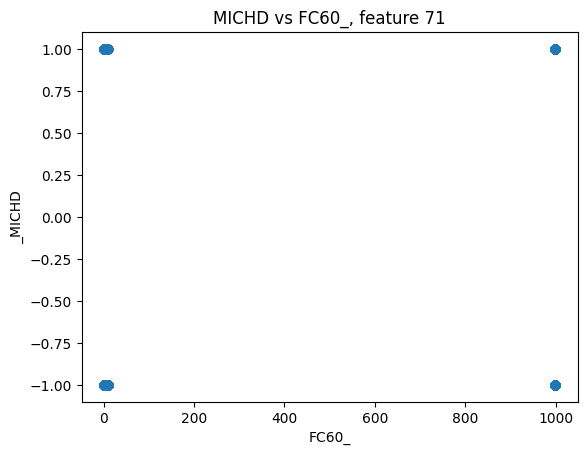

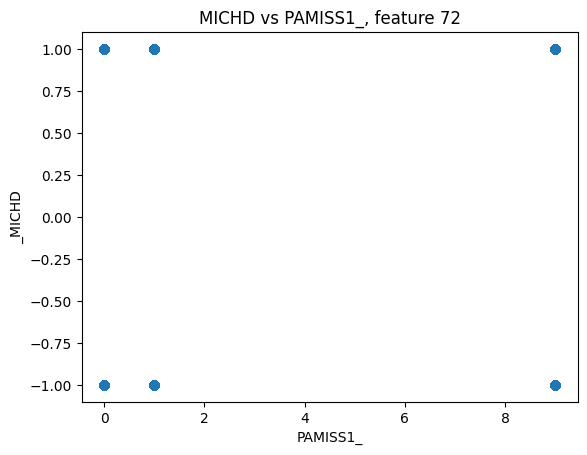

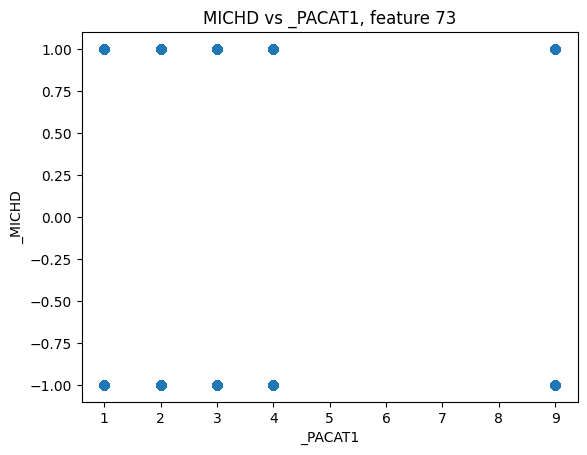

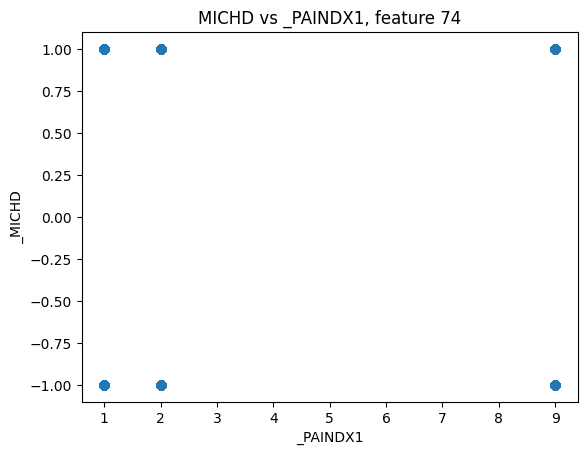

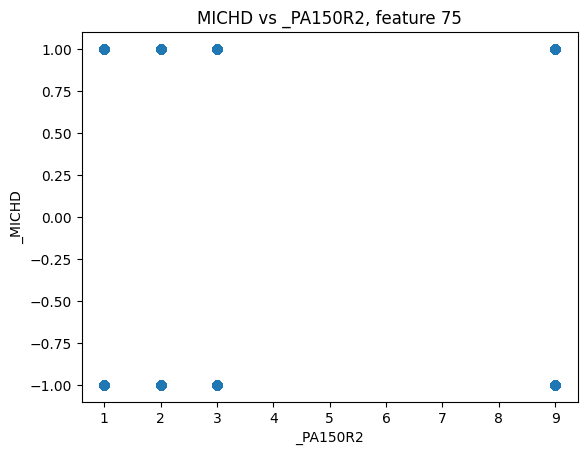

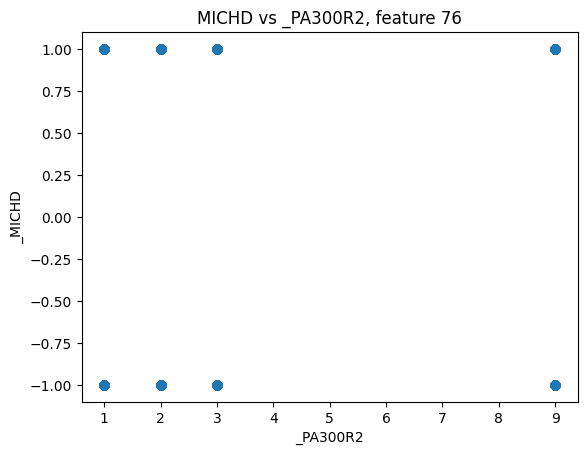

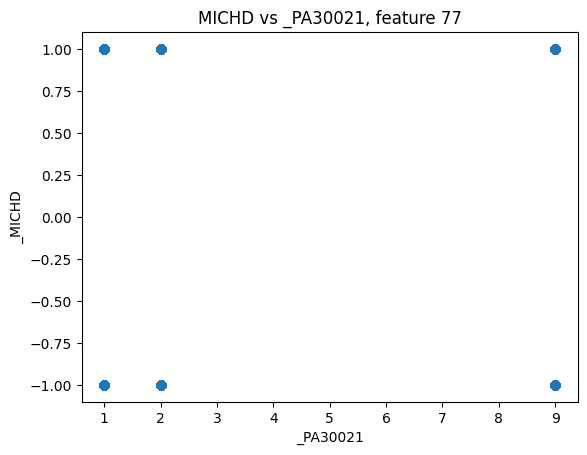

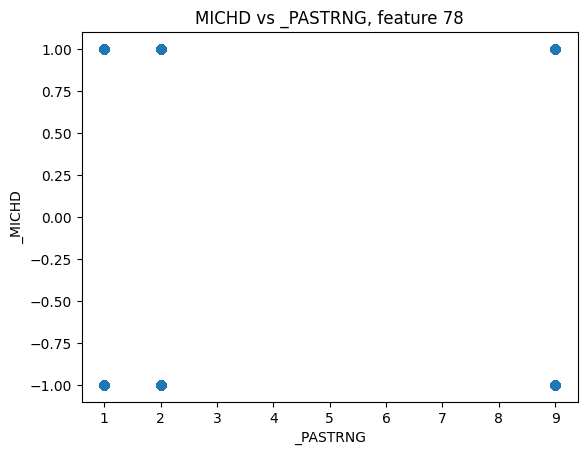

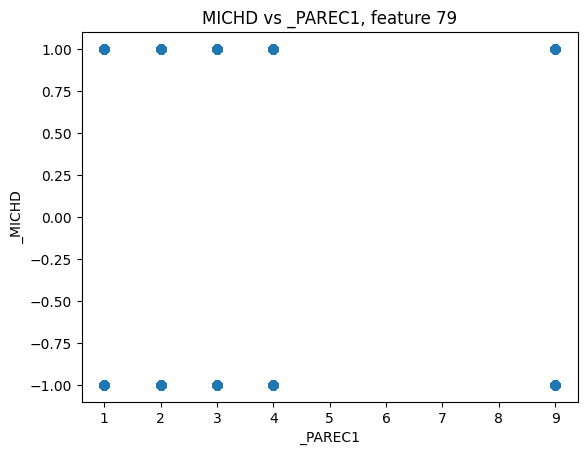

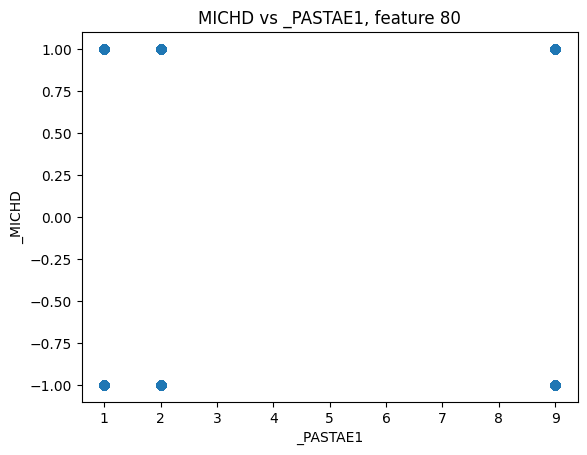

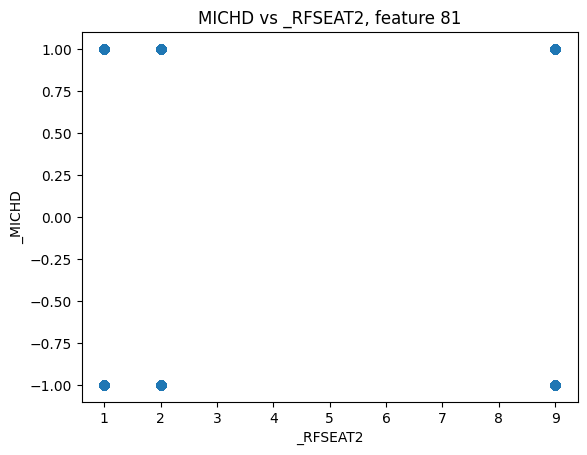

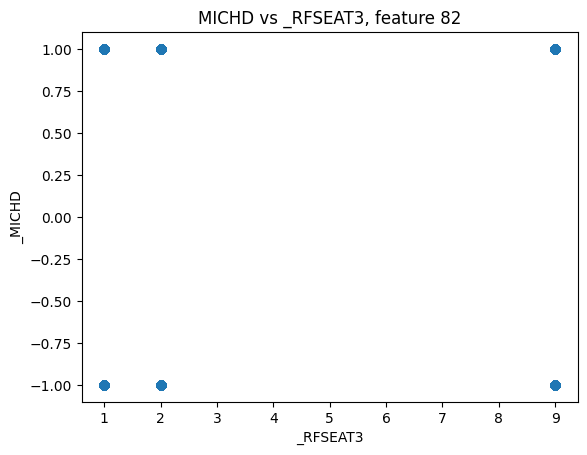

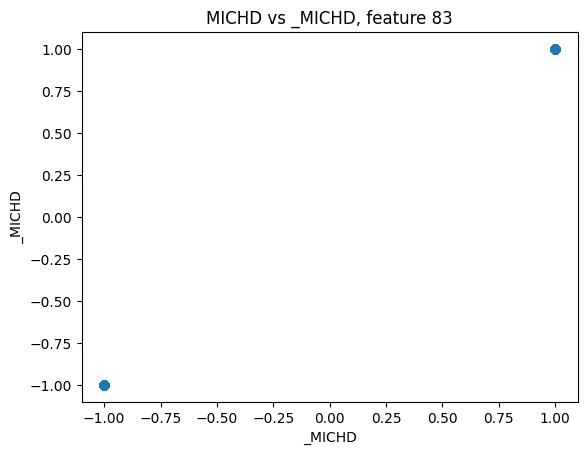

In [14]:
for i in range(len(L_feature)) :
    feature = L_feature[i]
    if feature in L_interest_health :
        plt.scatter(x_train_df_health[feature], x_train_df_health["_MICHD"])
        plt.xlabel(feature)
        plt.ylabel("_MICHD")
        plt.title(f"MICHD vs {feature}, feature {i}")
        plt.show()